# Phase 4 · 1/3 — The KPI and its time series

**VIGIE · Group BI 5** — Raed Meddeb · Ibrahim Grira · Salsabil Ben Elhadj · Salah Chebbi · Ines Ayed
Integrated Project, ESPRIT School of Business · Supervisors: Aymen Ben Brik and Hela Hammami

---

| Step | Content |
|---|---|
| 1 | Choice of the KPI and business justification |
| 2 | Building the series (account grain, zero weeks) |
| 3 | Spikes: identifying and treating the mass operations |
| 4 | Trend and regime changes |
| 5 | Seasonality |
| 6 | Autocorrelation (ACF / PACF) and stationarity |
| 7 | Consequences for modelling |

*The dates of the dataset were shifted by the anonymisation: we read durations and trends, never a real calendar.*

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT))
from vigie import config, data, series, style

warnings.filterwarnings("ignore")
style.apply()
C = config.COLORS
n = style.thousands

## 1. The chosen KPI: the weekly number of account closures

**Definition.** For each week (identified by its Monday), the number of accounts whose *first* closing date
falls in that week.

**Why this KPI?**

* **It is the direct measure of churn**: churn is defined by the closure of an account. The KPI therefore counts
  exactly the event we want to anticipate.
* **It is actionable**: forecasting next week's volume of closures makes it possible to size the retention and
  back-office teams, and to spot an abnormal week as soon as it departs from the forecast.
* **It is available at the right grain**: closing dates are brought back to the Monday, which gives a weekly
  series of about 200 points. Monthly, there would be only 47 points: too few for a recurrent network.

**Why not the closure rate?** A rate would require knowing, each week, the stock of open accounts. But the
opening date is blank for 68% of closed accounts: that stock cannot be rebuilt properly. The *number* of
closures only depends on the closing date, which is always filled in.

## 2. Building the series

In [2]:
df = data.load()
accounts = data.account_grain(df)                       # one row per account, first closing kept
closed = accounts[accounts["CHURN"] == 1]

serie = series.weekly_series(closed["ACCT_CLOSE_DATE"])  # count per Monday, zero weeks added

raw_rows = df[df["ACCOUNT_STATUS"] == "Closed"]
print(f"\"Closed\" rows in the file            : {n(len(raw_rows))}")
print(f"Closed accounts after de-duplication : {n(len(closed))}")
print(f"Period covered                       : {serie.index[0]:%d/%m/%Y} → {serie.index[-1]:%d/%m/%Y}")
print(f"Number of weeks                      : {len(serie)}  (≈ {len(serie) / 52:.1f} years)")
print(f"Weeks with no closure (added)        : {int((serie == 0).sum())}")
print(f"Total closures in the series         : {n(serie.sum())}")
assert serie.sum() == len(closed)                       # no closure lost or counted twice

"Closed" rows in the file            : 177,270
Closed accounts after de-duplication : 148,215
Period covered                       : 13/04/2020 → 19/02/2024
Number of weeks                      : 202  (≈ 3.9 years)
Weeks with no closure (added)        : 11
Total closures in the series         : 148,215


**Three precautions were taken:**

1. **Account grain.** Counting the rows of the file would give 177,270 closures instead of 148,215: the repeated
   accounts would inflate the series by nearly 20%.
2. **First closing date.** 11,807 accounts carry several dates; the first one is kept.
3. **Zero weeks.** A week missing from the file is not missing data: it is a week with **zero closure**. They are
   added, otherwise the series would not have a regular time step.

,count,mean,std,min,25%,50%,75%,max
Closures per week,202.0,733.7,2693.1,0.0,6.0,165.5,369.5,24295.0


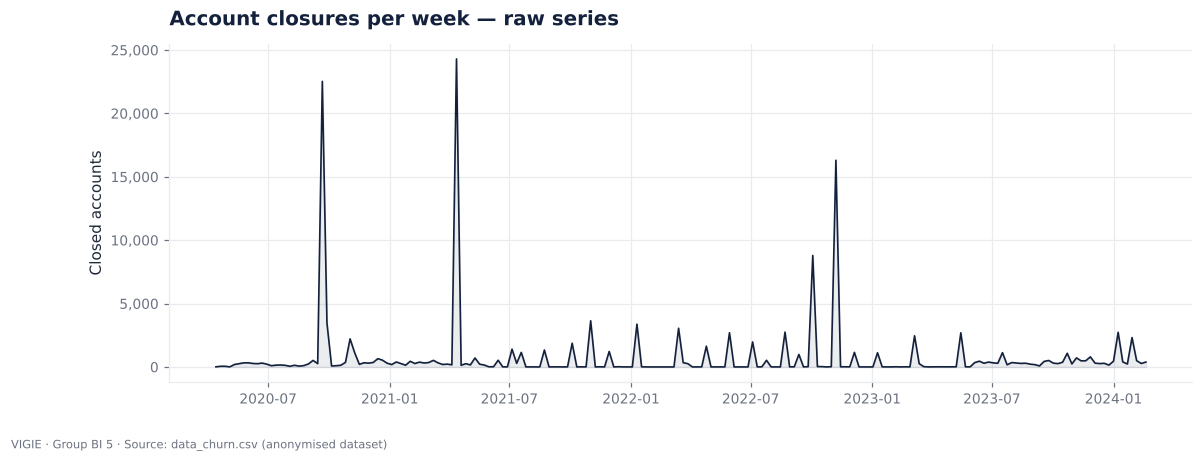

In [3]:
display(serie.describe().round(1).to_frame("Closures per week").T)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(serie.index, serie.values, color=C["ink"], lw=1.1)
ax.fill_between(serie.index, serie.values, color=C["ink"], alpha=0.08)
ax.yaxis.set_major_formatter(style.thousands)
ax.set_title("Account closures per week — raw series")
ax.set_ylabel("Closed accounts")
style.save(fig, "04_raw_series")
plt.show()

**Reading.** The raw series is unreadable: a few weeks crush everything else. The **median** is about 165
closures per week whereas the **mean** exceeds 730 and the maximum exceeds 24,000. Before any analysis, these
spikes have to be dealt with.

## 3. Spikes: the mass operations

### 3.1 Identification

**Rule.** Weeks are ranked by decreasing volume and we keep **the smallest set of weeks that adds up to half of
the closures**. The rule has no arbitrary threshold and reads directly in business terms: "these weeks weigh as
much as all the others together".

In [4]:
mass = series.mass_weeks(serie)                         # smallest set adding up to 50% of the volume
ranked = serie.sort_values(ascending=False)
concentration = pd.DataFrame({
    "Week": ranked.index[:8].strftime("%d/%m/%Y"),
    "Closures": ranked.values[:8],
    "Share of total": (ranked.values[:8] / serie.sum()),
    "Cumulative share": (ranked.cumsum().values[:8] / serie.sum()),
    "Mass operation": ["Yes" if s in mass else "No" for s in ranked.index[:8]],
})
display(concentration.style.format({"Closures": n, "Share of total": "{:.1%}", "Cumulative share": "{:.1%}"}).hide(axis="index"))
print(f"{len(mass)} weeks out of {len(serie)} ({len(mass) / len(serie):.1%}) carry {serie[mass].sum() / serie.sum():.1%} of the closures.")

Week,Closures,Share of total,Cumulative share,Mass operation
12/04/2021,"24,295",16.4%,16.4%,Yes
21/09/2020,"22,525",15.2%,31.6%,Yes
07/11/2022,"16,301",11.0%,42.6%,Yes
03/10/2022,"8,794",5.9%,48.5%,Yes
01/11/2021,"3,641",2.5%,51.0%,Yes
28/09/2020,"3,470",2.3%,53.3%,No
10/01/2022,"3,376",2.3%,55.6%,No
14/03/2022,"3,052",2.1%,57.7%,No


5 weeks out of 202 (2.5%) carry 51.0% of the closures.


In [5]:
# Are these weeks different in nature? We look at the closure reason.
in_mass = closed["ACCT_CLOSE_DATE"].isin(mass)
nature = pd.DataFrame({
    "Closed accounts": closed.groupby(in_mass).size(),
    "Share of reason \"Other\" (RSN01)": closed.groupby(in_mass)["CLOSURE_REASON"].apply(lambda s: (s == "RSN01").mean()),
    "Share of accounts with no balance": closed.groupby(in_mass)["ACCT_BALANCE"].apply(lambda s: s.isna().mean()),
})
nature.index = ["Ordinary weeks", "Mass weeks"]
display(nature.style.format({"Closed accounts": n, "Share of reason \"Other\" (RSN01)": "{:.1%}",
                             "Share of accounts with no balance": "{:.1%}"}))

,Closed accounts,"Share of reason ""Other"" (RSN01)",Share of accounts with no balance
Ordinary weeks,"72,659",61.9%,53.8%
Mass weeks,"75,556",99.5%,81.3%


**Reading.** Five weeks — 2.5% of the series — concentrate **51% of the closures**. This matches the finding of
the data description document. These weeks do not look like the others: the closure reason is "Other" in 99.5%
of cases (62% in the other weeks) and 81% of the accounts concerned no longer have balance information (54% in
the other weeks). They are **mass operations** (batch closures), not individual customer departures.

### 3.2 Treatment: a corrected series

Three treatments were possible:

| Option | Principle | Why we do not keep / keep it |
|---|---|---|
| Leave as is | the model learns the spikes | impossible: a mass operation is a management decision, it cannot be predicted from the past of the series, and it dominates the error |
| Intervention variable | add a 0/1 "mass week" flag | the flag is only known *after the fact*: it cannot be used to forecast the future |
| **Corrected series** | replace the value of the 5 weeks by an ordinary level | **kept**: we forecast the ordinary closing activity, which is what the business can anticipate |

**Correction applied.** Each mass week is replaced by the **median of the 4 previous and the 4 following weeks**
(other mass weeks excluded). The median is robust to neighbouring spikes. The mass-week flag is kept aside for
display: these operations are not hidden, they are taken out of the signal to forecast.

In [6]:
corrected = series.correct_mass_weeks(serie, mass)
before_after = pd.DataFrame({"Raw series": serie[mass], "Corrected series": corrected[mass]})
before_after.index = before_after.index.strftime("%d/%m/%Y")
display(before_after.style.format(n))
print(f"Raw total: {n(serie.sum())}   |   Corrected total: {n(corrected.sum())}   "
      f"|   Volume removed: {n(serie.sum() - corrected.sum())} ({1 - corrected.sum() / serie.sum():.1%})")
display(corrected.describe().round(1).to_frame("Corrected series").T)

,Raw series,Corrected series
week,,
21/09/2020,"22,525",186
12/04/2021,"24,295",208
01/11/2021,"3,641",4
03/10/2022,"8,794",20
07/11/2022,"16,301",16


Raw total: 148,215   |   Corrected total: 73,093   |   Volume removed: 75,122 (50.7%)


,count,mean,std,min,25%,50%,75%,max
Corrected series,202.0,361.8,655.2,0.0,5.2,148.5,340.2,3470.0


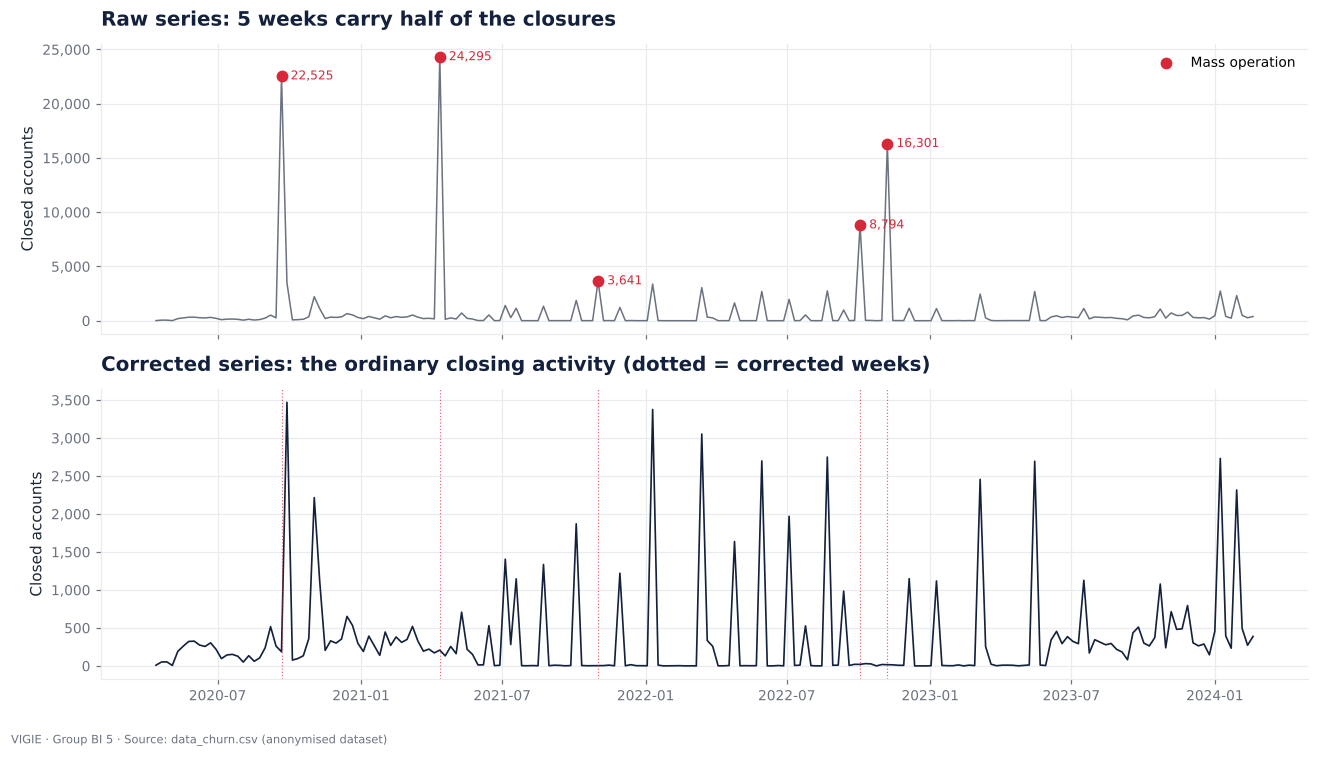

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.6), sharex=True)
axes[0].plot(serie.index, serie.values, color=C["grey"], lw=1)
axes[0].scatter(mass, serie[mass], color=C["churn"], zorder=3, s=45, label="Mass operation")
for s in mass:
    axes[0].annotate(n(serie[s]), (s, serie[s]), textcoords="offset points", xytext=(6, -2), fontsize=8, color=C["churn"])
axes[0].set_title("Raw series: 5 weeks carry half of the closures")
axes[0].legend(loc="upper right")
axes[1].plot(corrected.index, corrected.values, color=C["ink"], lw=1.1)
for s in mass:
    axes[1].axvline(s, color=C["churn"], lw=0.8, ls=":", alpha=0.7)
axes[1].set_title("Corrected series: the ordinary closing activity (dotted = corrected weeks)")
for ax in axes:
    ax.yaxis.set_major_formatter(style.thousands)
    ax.set_ylabel("Closed accounts")
fig.tight_layout()
style.save(fig, "04_corrected_series")
plt.show()

Once the five mass operations are removed, the series becomes readable again. It remains **very irregular**:
22 weeks still exceed 1,000 closures (11% of the weeks, 60% of the corrected volume). They are too many and too
recurrent to be treated as exceptions: they are part of normal operation and are left in the series. This is the
main difficulty of the forecast.

## 4. Trend and regime changes

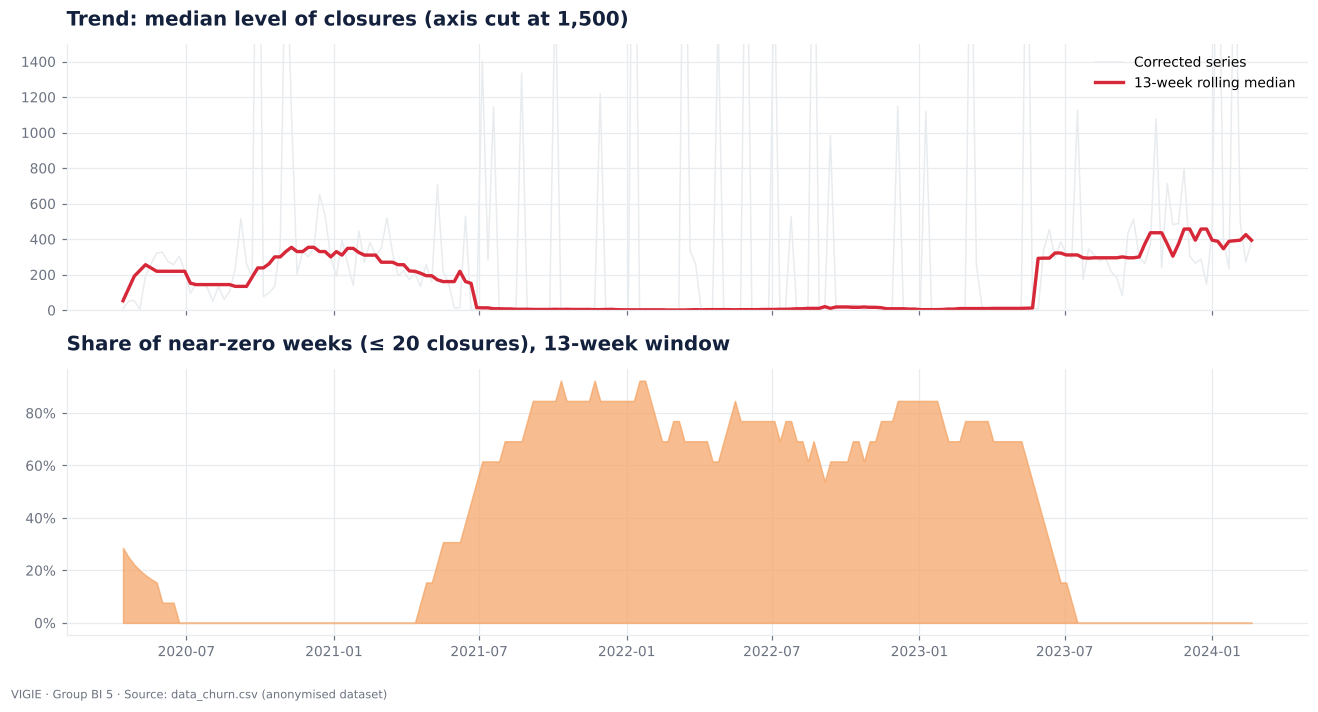

In [8]:
rolling_median = corrected.rolling(13, center=True, min_periods=7).median()      # ≈ one quarter
near_zero_share = (corrected <= 20).rolling(13, center=True, min_periods=7).mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 6.2), sharex=True)
axes[0].plot(corrected.index, corrected.values, color=C["mist"], lw=1, label="Corrected series")
axes[0].plot(rolling_median.index, rolling_median.values, color=C["churn"], lw=2.2, label="13-week rolling median")
axes[0].set_ylim(0, 1500)
axes[0].set_title("Trend: median level of closures (axis cut at 1,500)")
axes[0].legend(loc="upper right")
axes[1].fill_between(near_zero_share.index, near_zero_share.values, color=C["amber"], alpha=0.7)
axes[1].yaxis.set_major_formatter(style.percent)
axes[1].set_title("Share of near-zero weeks (≤ 20 closures), 13-week window")
fig.tight_layout()
style.save(fig, "04_trend_regimes")
plt.show()

In [9]:
# Splitting into regimes: we locate the changes of the state "near-zero weeks are the majority".
state = (near_zero_share > 0.5).astype(int)
breaks = state.index[state.diff().abs() == 1]
bounds = [corrected.index[0], *breaks, corrected.index[-1] + pd.Timedelta(weeks=1)]
regimes = []
for i, (a, b) in enumerate(zip(bounds, bounds[1:]), start=1):
    block = corrected[(corrected.index >= a) & (corrected.index < b)]
    regimes.append({
        "Regime": i, "Start": f"{block.index[0]:%d/%m/%Y}", "End": f"{block.index[-1]:%d/%m/%Y}", "Weeks": len(block),
        "Median": block.median(), "Mean": round(block.mean(), 1),
        "Weeks ≤ 20 closures": f"{(block <= 20).mean():.0%}", "Zero weeks": int((block == 0).sum()),
        "Maximum": int(block.max()),
    })
regimes = pd.DataFrame(regimes).set_index("Regime")
display(regimes)

,Start,End,Weeks,Median,Mean,Weeks ≤ 20 closures,Zero weeks,Maximum
Regime,,,,,,,,
1,13/04/2020,21/06/2021,63,221.0,334.0,8%,0,3470
2,28/06/2021,22/05/2023,100,6.0,329.8,75%,11,3376
3,29/05/2023,19/02/2024,39,322.0,488.9,3%,0,2732


**Reading — trend and breaks.** The series has no steady upward or downward trend. It changes **regime**:

* **Regime 1 — continuous flow (63 weeks).** Closures every week, 221 at the median.
* **Regime 2 — batch processing (100 weeks).** Three weeks out of four are almost empty (median: 6) and closures
  arrive in batches several weeks apart. The 11 zero weeks all belong to this regime. Yet the *mean* (330) stays
  close to that of regime 1: the volume is the same, only the rhythm changes.
* **Regime 3 — back to continuous flow (39 weeks).** Closures every week again, at a higher level than at the
  start (median 322).

This is the most important fact of the analysis: the *rhythm* of the series depends on **how closures are
processed** (as they come, or in batches) as much as on customer behaviour. The test period — the last 40 weeks —
coincides almost exactly with regime 3 (39 weeks).

## 5. Seasonality

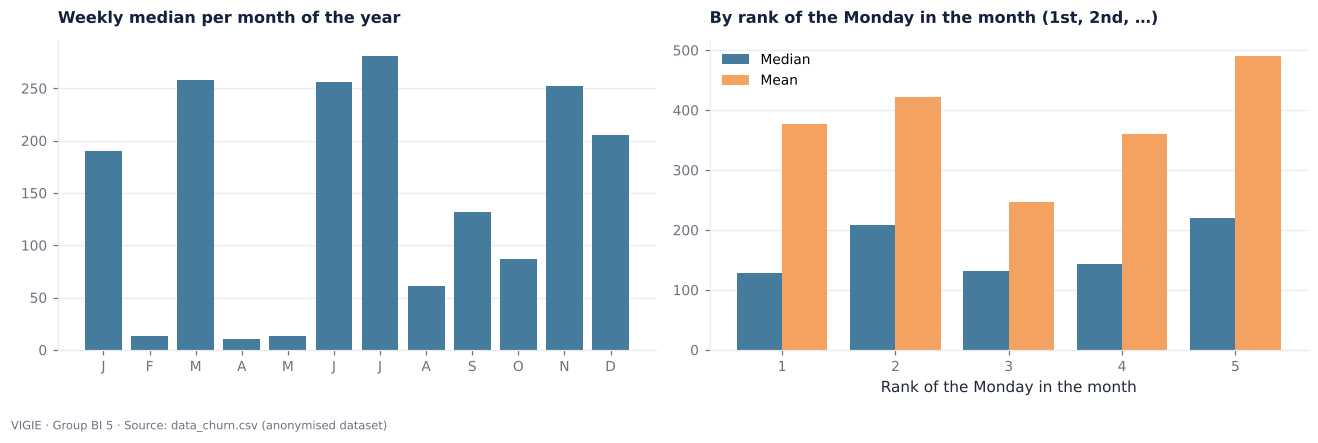

,Weeks,Median,Total
Year,,,
2020,38,228.5,14476
2021,52,145.0,13923
2022,52,5.5,18983
2023,52,263.5,18426
2024,8,425.5,7285


,Median,Mean
Rank of the Monday in the month,,
1,128.0,377.0
2,208.0,421.0
3,132.0,246.0
4,142.0,359.0
5,220.0,490.0


In [10]:
per_month = corrected.groupby(corrected.index.month).median()
rank_in_month = ((corrected.index.day - 1) // 7 + 1)
per_rank = corrected.groupby(rank_in_month).agg(["median", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(per_month.index, per_month.values, color=C["sky"])
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
axes[0].set_title("Weekly median per month of the year", fontsize=10.5)
axes[1].bar(per_rank.index - 0.2, per_rank["median"], width=0.4, color=C["sky"], label="Median")
axes[1].bar(per_rank.index + 0.2, per_rank["mean"], width=0.4, color=C["amber"], label="Mean")
axes[1].set_title("By rank of the Monday in the month (1st, 2nd, …)", fontsize=10.5)
axes[1].set_xlabel("Rank of the Monday in the month")
axes[1].legend()
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
style.save(fig, "04_seasonality")
plt.show()

per_year = corrected.groupby(corrected.index.year).agg(Weeks="size", Median="median", Total="sum")
per_year.index.name = "Year"
display(per_year)
display(per_rank.round(0).rename(columns={"median": "Median", "mean": "Mean"}).rename_axis("Rank of the Monday in the month"))

**Reading — seasonality.**

* **Annual seasonality: cannot be demonstrated.** The series covers less than four years, two of which in "batch"
  regime. The gaps between months mostly reflect the regime these months fall in, not an annual cycle. Besides,
  since the dates are shifted, a month of the dataset does not correspond to a real month.
* **"Rank in the month" effect: none.** No rank of Monday stands out in a stable way: medians range from 128 to
  220 and means from 246 to 490, with no readable order. Batches therefore do not fall on a fixed date in the month.

We therefore keep **no calendar seasonal component**. If there is a rhythm, it is to be found in the series
itself: this is what autocorrelation is for.

## 6. Autocorrelation and stationarity

We work on `log(1 + closures)`: the logarithmic transform brings the spikes back to a scale comparable with the
rest of the series (the `+ 1` handles the zero weeks).

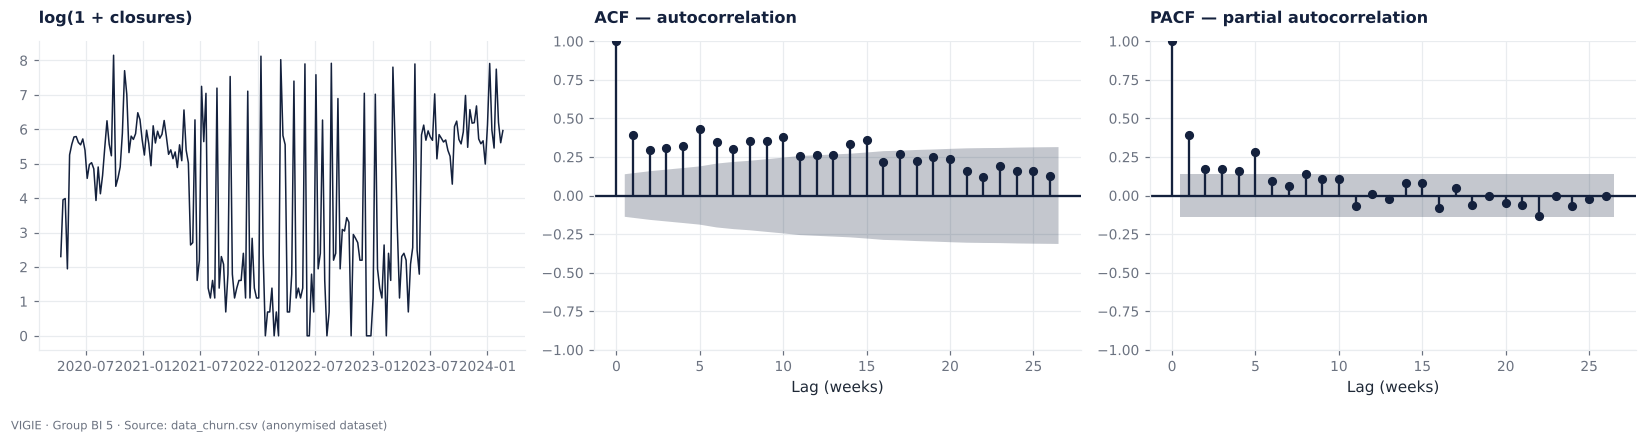

Lag (weeks),1,2,3,4,5,6,7,8,9,10,11,12
ACF,0.39,0.30,0.31,0.32,0.43,0.35,0.30,0.35,0.36,0.38,0.26,0.26
PACF,0.39,0.17,0.17,0.16,0.28,0.09,0.06,0.14,0.11,0.11,-0.06,0.01


95% significance threshold: ± 0.14


In [11]:
log_serie = np.log1p(corrected)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(log_serie.index, log_serie.values, color=C["ink"], lw=1)
axes[0].set_title("log(1 + closures)", fontsize=10.5)
plot_acf(log_serie, lags=26, ax=axes[1], color=C["ink"], vlines_kwargs={"colors": C["ink"]})
axes[1].set_title("ACF — autocorrelation", fontsize=10.5)
plot_pacf(log_serie, lags=26, ax=axes[2], color=C["ink"], vlines_kwargs={"colors": C["ink"]}, method="ywm")
axes[2].set_title("PACF — partial autocorrelation", fontsize=10.5)
for ax in axes[1:]:
    ax.set_xlabel("Lag (weeks)")
fig.tight_layout()
style.save(fig, "04_acf_pacf")
plt.show()

ac, pac = acf(log_serie, nlags=12), pacf(log_serie, nlags=12, method="ywm")
display(pd.DataFrame({"ACF": ac[1:], "PACF": pac[1:]}, index=pd.RangeIndex(1, 13, name="Lag (weeks)")).round(2).T)
print(f"95% significance threshold: ± {1.96 / np.sqrt(len(log_serie)):.2f}")

In [12]:
def stationarity_tests(s: pd.Series, name: str) -> dict:
    adf_stat, adf_p = adfuller(s.dropna(), autolag="AIC")[:2]
    kpss_stat, kpss_p = kpss(s.dropna(), regression="c", nlags="auto")[:2]
    return {"Series": name, "ADF — statistic": round(adf_stat, 2), "ADF — p-value": round(adf_p, 4),
            "ADF: stationary?": "Yes" if adf_p < 0.05 else "No",
            "KPSS — statistic": round(kpss_stat, 2), "KPSS — p-value": round(kpss_p, 3),
            "KPSS: stationary?": "Yes" if kpss_p > 0.05 else "No"}


stationarity = pd.DataFrame([
    stationarity_tests(corrected.astype(float), "Corrected series"),
    stationarity_tests(log_serie, "log(1 + series)"),
    stationarity_tests(log_serie.diff(), "log(1 + series), differenced"),
]).set_index("Series")
display(stationarity)

,ADF — statistic,ADF — p-value,ADF: stationary?,KPSS — statistic,KPSS — p-value,KPSS: stationary?
Series,,,,,,
Corrected series,-11.64,0.0000,Yes,0.17,0.100,Yes
log(1 + series),-1.14,0.6982,No,0.49,0.043,No
"log(1 + series), differenced",-8.54,0.0000,Yes,0.16,0.100,Yes


**How to read the two tests.** They ask the question in opposite directions:

* **ADF** — null hypothesis: the series is *not* stationary. A p-value < 0.05 concludes that it is stationary.
* **KPSS** — null hypothesis: the series *is* stationary. A p-value < 0.05 concludes that it is not.

When both tests agree, the conclusion is solid; when they diverge, the series sits on the border (typically:
stationary by pieces, with level shifts).

**Reading — autocorrelation.**

* The **ACF** is significant at every lag from 1 to 12 and decays very slowly (from 0.39 to 0.26): a week
  resembles its neighbours because it belongs to the same **regime**. This persistence is the signature of a
  level that changes over time.
* The **PACF** is clear at lags 1 to 5 (0.39, then 0.16 to 0.28), then falls back around the threshold. The peak
  at **lag 5** (ACF 0.43, the strongest) points to a rhythm of about five weeks: this is the typical spacing of
  the batches of regime 2.
* Consequence: an **8-week window** covers every useful lag, including the five-week rhythm.

**Reading — stationarity.**

* On the **logarithmic** scale, the one we model on, both tests agree: the series is **not stationary**
  (ADF: p = 0.70; KPSS: p = 0.04). Regime changes are level shifts.
* **One differencing is enough**: the differenced series is stationary for both tests. An ARIMA model will
  therefore need `d = 1`.
* On the raw level, the tests conclude that the series is stationary, but this is misleading: the spikes
  dominate the variance and hide the level shifts. One more reason to work in logarithm.

## 7. What the analysis implies for modelling

In [13]:
significant = [k for k in range(1, 13) if abs(ac[k]) > 1.96 / np.sqrt(len(log_serie))]
findings = {
    "Lags with a significant ACF (1 to 12)": significant,
    "ACF at lag 1": round(float(ac[1]), 2),
    "Highest ACF (lags 1 to 12)": f"{max(ac[1:], key=abs):.2f} at lag {int(np.argmax(np.abs(ac[1:]))) + 1}",
    "Zero weeks": int((corrected == 0).sum()),
    "Coefficient of variation (std dev / mean)": round(float(corrected.std() / corrected.mean()), 2),
}
display(pd.Series(findings, name="Value").to_frame())

,Value
Lags with a significant ACF (1 to 12),"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]"
ACF at lag 1,0.39
Highest ACF (lags 1 to 12),0.43 at lag 5
Zero weeks,11
Coefficient of variation (std dev / mean),1.81


| Finding | Modelling decision |
|---|---|
| 5 mass operations = 51% of the closures | **Corrected** series; mass flag kept for display |
| Highly skewed distribution, 11 zero weeks | `log(1 + x)` transform; absolute error as the loss function |
| **MAPE undefined** on zero weeks | Evaluation with **MAE** and **RMSE** only |
| Three regimes, no calendar seasonality | No seasonal component; strict **chronological** split |
| PACF useful up to 5 weeks, ACF peak at 5 | **8-week sliding window** |
| Not stationary in log, stationary after differencing | Reference ARIMA with `d = 1` |
| Only ≈ 200 points, recurrent spikes | **Small** network (one layer); mandatory comparison with simple references |

**What can reasonably be expected.** With 202 weeks, three regimes and recurrent spikes, no model will forecast
the spikes. The realistic goal is to forecast the **ordinary level** of closures correctly, and to do better than
the naive forecast. This is what the next notebook measures.

➡ Next: `02_lstm_rnn.ipynb`.

In [14]:
# Saving the series (a weekly aggregate: no individual data) for the following notebooks.
config.ML_RESULTS.mkdir(parents=True, exist_ok=True)
output = {
    "kpi": "Weekly number of account closures",
    "grain": "account (first closing date)",
    "source_sha256": data.fingerprint()["sha256"],
    "weeks": [str(s.date()) for s in serie.index],
    "raw": [int(v) for v in serie.values],
    "corrected": [int(v) for v in corrected.values],
    "mass_weeks": [str(s.date()) for s in mass],
    "regimes": regimes.reset_index().to_dict(orient="records"),
}
(config.ML_RESULTS / "weekly_closures.json").write_text(json.dumps(output, ensure_ascii=False, indent=1), encoding="utf-8")
print("Series saved: 04_machine_learning/results/weekly_closures.json")

Series saved: 04_machine_learning/results/weekly_closures.json
